<a href="https://colab.research.google.com/github/Abanob-Adly/Workforce/blob/main/notebooks/Base_Workforce_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score
)

In [51]:
train_df = pd.read_csv('workforce_train_data.csv').drop(columns=['job_id'])
test_df  = pd.read_csv('workforce_test_data.csv').drop(columns=['job_id'])

X_train = train_df.drop(columns=['future_outlook'])
y_train = train_df['future_outlook']

X_test = test_df.drop(columns=['future_outlook'])
y_test = test_df['future_outlook']

In [52]:
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
display(X_train.head())
X_train.info()

Train shape: (16000, 18) | Test shape: (4000, 18)


,job_title,industry,country,company_size,employment_type,required_education,experience_level,median_salary_usd,remote_work_ratio,ai_adoption_level,top_skills_required,skill_transferability,repetitive_task_score,automation_risk_pct,projected_growth_2030,retraining_feasibility_score,workplace_flexibility_index,estimated_openings_2030
0,Nurse Practitioner,Healthcare,United Kingdom,Startup (1-50),Full-time,Master's,Mid,121348,0.5,Moderate,"Patient Care, Diagnostics, Clinical Protocols",0.80,0.26,11.8,41.2,0.85,0.5,7857
1,AI & Machine Learning Engineer,Technology,United Kingdom,Startup (1-50),Full-time,Master's,Mid,165226,1.0,Transformative,"Python, PyTorch, LLMs, MLOps",0.98,0.15,4.7,34.7,0.92,0.8,5946
2,AI & Machine Learning Engineer,Technology,United States,Enterprise (500+),Full-time,Master's,Mid,143484,0.5,Transformative,"Python, PyTorch, LLMs, MLOps",0.87,0.17,10.8,31.2,0.93,0.5,5911
3,Data Scientist,Technology,Australia,Startup (1-50),Full-time,Master's,Entry,104681,0.0,High,"Python, SQL, Statistics, Machine Learning",0.92,0.25,19.8,26.3,0.94,0.2,5624
4,Nurse Practitioner,Healthcare,United States,Enterprise (500+),Full-time,Master's,Senior,166533,0.5,Moderate,"Patient Care, Diagnostics, Clinical Protocols",0.98,0.08,1.0,46.5,0.95,0.5,8197


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   job_title                     16000 non-null  object 
 1   industry                      16000 non-null  object 
 2   country                       16000 non-null  object 
 3   company_size                  16000 non-null  object 
 4   employment_type               16000 non-null  object 
 5   required_education            16000 non-null  object 
 6   experience_level              16000 non-null  object 
 7   median_salary_usd             16000 non-null  int64  
 8   remote_work_ratio             16000 non-null  float64
 9   ai_adoption_level             16000 non-null  object 
 10  top_skills_required           16000 non-null  object 
 11  skill_transferability         16000 non-null  float64
 12  repetitive_task_score         16000 non-null  float64
 13  a

In [53]:
print("\nTarget Distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))


Target Distribution (%):
future_outlook
High Demand            43.74
At Risk / Declining    29.71
Transforming           21.56
Stable                  4.99
Name: proportion, dtype: float64


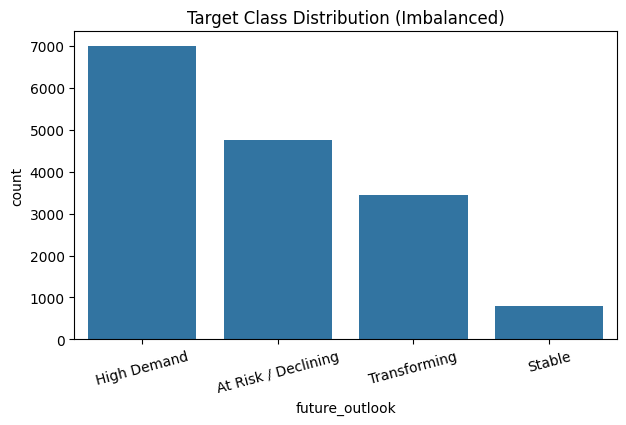

In [54]:
plt.figure(figsize=(7, 4))
sns.countplot(data=train_df, x='future_outlook', order=train_df['future_outlook'].value_counts().index)
plt.title('Target Class Distribution (Imbalanced)')
plt.xticks(rotation=15)
plt.show()
